# 04 · Modelling and training

Here is the full model and the recipe that trained the 15 released checkpoints. A short demo cell exercises the real
training code on a small subset. The training curves come from the actual runs.

_This model was developed for a research competition and is not a medical device._

In [1]:
# Setup: every path comes from configs/final.yaml (milk10k.config); nothing here downloads data.
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RELEASE = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(RELEASE / "src") not in sys.path:
    sys.path.insert(0, str(RELEASE / "src"))  # works without `pip install -e .`
from milk10k.config import load_config
import inspect

import torch

cfg = load_config()
DATA = cfg["paths"]["data_dir"]  # prepared MILK10k (data/README.md); override with MILK10K_DATA_DIR

# "data:<file>" = under DATA; anything else is relative to the release root.
INPUTS = {
    "train_meta": "data:train_metadata.csv",
    "test_meta": "data:test_metadata.csv",
    "folds": "data/folds.csv",
    "config": "configs/final.yaml",
    "history": "results/training_history.csv",
    "runtime": "results/kaggle_runtime.json",
    "manifest": "models/final-P1a-kg/manifest.json"
}
OUTPUTS = {
    "fig_lr": "results/figures/04_lr_schedule.png",
    "fig_history": "results/figures/04_training_history.png",
    "table_best_epochs": "results/tables/04_best_epochs.csv",
    "demo_dir": "results/demo_training/"
}


def inp(key):
    v = INPUTS[key]
    return DATA / v[5:] if v.startswith("data:") else RELEASE / v


def out(key):
    p = RELEASE / OUTPUTS[key]
    p.parent.mkdir(parents=True, exist_ok=True)
    return p


def savefig(key):
    plt.tight_layout()
    plt.savefig(out(key), dpi=120)
    plt.show()


missing = [k for k in INPUTS if not inp(k).exists()]
import os  # noqa: E402
print("data dir from:", "MILK10K_DATA_DIR" if os.environ.get("MILK10K_DATA_DIR") else "configs/final.yaml")
print("checkpoints from:", "MILK10K_CHECKPOINT_DIR" if os.environ.get("MILK10K_CHECKPOINT_DIR") else "configs/final.yaml")
print("missing inputs:", missing or "none")

data dir from: MILK10K_DATA_DIR
checkpoints from: configs/final.yaml
missing inputs: none


## 1. Configuration
Everything that defines the released model lives in one file. Its values mirror the `args` stored in every checkpoint
(verified in `models/final-P1a-kg/manifest.json`).

In [2]:
print(inp("config").read_text())

# final-P1a-kg: the released model (pooled OOF score 0.6505).
# Values mirror the "args" stored in every released checkpoint (verified by models/final-P1a-kg/manifest.json).
name: final-P1a-kg

paths:                                   # relative to the release root; see milk10k.config
  data_dir: data/raw                     # prepared layout; override with env MILK10K_DATA_DIR
  source_dir: data/raw/_source           # the six ISIC release files (data/README.md)
  folds: data/folds.csv                  # fixed 5-fold assignment; never regenerate
  checkpoint_dir: models/final-P1a-kg
  results_dir: results
  sample_dir: sample

recipe:                                  # one training run = one seed x 5 folds
  backbone: resnet18.a1_in1k             # timm name, used for BOTH image streams
  pretrained: true                       # ImageNet-1k init from Hugging Face (MODEL_CARD.md); needs network once
  d: 256                                 # fusion width
  img_size: 288                

## 2. Architecture
Two `resnet18.a1_in1k` encoders, one for dermoscopy and one for the clinical photo, have their pooled features
projected to width 256. A small MLP encodes the metadata. Four tokens (CLS, derm, clin, tab) then pass through two
Transformer encoder layers. Two heads predict the 11 classes and malignancy. A missing clinical image is replaced
by a learned `[NULL]` token. Spatial cross-attention between the streams exists in the code but is off: it was tried
and dropped (`docs/experiment_log.md`). How big is the model, and where are its parameters?

In [3]:
from milk10k.models import FocalLoss, MILKFusionNet

r = cfg["recipe"]
model = MILKFusionNet(derm_name=r["backbone"], clin_name=r["backbone"], d=r["d"], pretrained=False,
                      xattn_layers=r["xattn_layers"])


def n_params(m):
    return sum(p.numel() for p in m.parameters())


print(f"total parameters: {n_params(model):,}")
display(pd.Series({name: n_params(mod) for name, mod in model.named_children()}, name="parameters"))
print(inspect.getsource(MILKFusionNet))

<release>/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


total parameters: 23,749,008


derm         11176512
clin         11176512
derm_proj      131328
clin_proj      131328
tab             73988
fusion        1054208
norm              512
head_cls         2827
head_bin          257
xattn               0
Name: parameters, dtype: int64

class MILKFusionNet(nn.Module):
    """Derm backbone + clinical backbone + tabular MLP, fused as tokens by a small Transformer.

    A missing clinical image (clin_mask == False) is replaced by a learned [NULL] token.
    With xattn_layers > 0 (P4a), the two image streams keep their feature-map tokens (9×9 at 288 px for
    ResNet18), exchange information through `xattn_layers` CrossAttnBlocks, and are then mean-pooled into the
    same 4-token fusion. xattn_layers = 0 is the original pooled model, with identical parameters.
    Returns (11-class logits, binary malignancy logit).
    """

    def __init__(self,
                 derm_name: str = "convnext_small.fb_in22k_ft_in1k_384",
                 clin_name: str = "swin_base_patch4_window12_384.ms_in22k_ft_in1k",
                 d: int = 512, n_classes: int = len(CLASSES), pretrained: bool = True, xattn_layers: int = 0):
        super().__init__()
        self.derm = timm.create_model(derm_name, pretrained=pretrained, num_classes=0)

23.7 M parameters, almost all in the two ResNet18 encoders (11.2 M each). The fusion Transformer adds 1.05 M and the
metadata MLP 74 k.

## 3. Loss, sampler, optimiser, schedule
- Loss: an 11-class **focal loss** (γ = 2) plus **BCE** on the malignancy head.
- **Sqrt-balanced sampling** (weight ∝ class frequency^-0.5): the tail classes are seen more often without being over-repeated.
- **AdamW** with backbone LR 3e-4 and 10× (3e-3) for the heads, fusion and metadata MLP; weight decay 0.05.
- **Linear warmup over 5% of the steps, then cosine decay to 0**, stepped per batch; fp16 autocast with gradient scaling.
- The best epoch of each fold is chosen on that fold's validation score.

In [4]:
from milk10k.dataset import make_sqrt_balanced_sampler
from milk10k.train import train_fold, warmup_cosine

for obj in (FocalLoss, make_sqrt_balanced_sampler, warmup_cosine, train_fold):
    print(inspect.getsource(obj))

class FocalLoss(nn.Module):
    """Multi-class focal loss with optional per-class weights `alpha`."""

    def __init__(self, gamma: float = 2.0, alpha: Optional[torch.Tensor] = None):
        super().__init__()
        self.gamma = gamma
        self.register_buffer("alpha", alpha)

    def forward(self, logits, target):
        logp = F.log_softmax(logits, dim=1)
        ce = F.nll_loss(logp, target, weight=self.alpha, reduction="none")
        pt = logp.gather(1, target[:, None]).squeeze(1).exp()
        return ((1 - pt) ** self.gamma * ce).mean()

def make_sqrt_balanced_sampler(labels: pd.Series,
                               num_samples: Optional[int] = None) -> WeightedRandomSampler:
    """Sample weight ∝ class_freq^-0.5 (softer than full inverse-frequency)."""
    freq = labels.map(labels.value_counts())
    w = torch.tensor((1.0 / np.sqrt(freq)).to_numpy(), dtype=torch.double)
    return WeightedRandomSampler(w, num_samples=num_samples or len(w), replacement=True)

def warmup

optimizer steps per epoch by fold: {np.int64(0): 131, np.int64(1): 131, np.int64(2): 131, np.int64(3): 131, np.int64(4): 131}


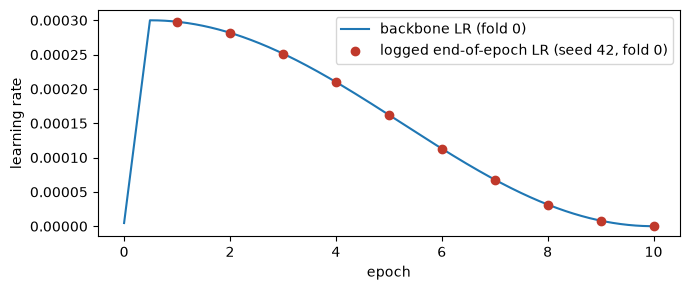

In [5]:
folds = pd.read_csv(inp("folds"))
steps = {k: int((folds.fold != k).sum()) // r["batch_size"] for k in sorted(folds.fold.unique())}  # drop_last=True
print("optimizer steps per epoch by fold:", steps)
f = warmup_cosine(r["epochs"] * steps[0])
lr = np.array([r["lr"] * f(s) for s in range(r["epochs"] * steps[0])])
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(np.arange(len(lr)) / steps[0], lr, label="backbone LR (fold 0)")
hist = pd.read_csv(inp("history"))
h0 = hist[(hist.seed == 42) & (hist.fold == 0)]
ax.scatter(h0.epoch, h0.lr_end, color="#c0392b", zorder=3, label="logged end-of-epoch LR (seed 42, fold 0)")
ax.set_xlabel("epoch")
ax.set_ylabel("learning rate")
ax.legend()
savefig("fig_lr")

The logged end-of-epoch learning rates fall exactly on this schedule, which reaches zero at the last step.

## 4. Pretrained weights
Training starts from `timm/resnet18.a1_in1k` (Hugging Face revision `491b427b45c94c7fb0e78b5474cc919aff584bbf`,
Apache-2.0, trained on ImageNet-1k; see `MODEL_CARD.md`). `timm` downloads it on first use. To fetch it ahead of an
offline run:

```bash
python -c "import timm; timm.create_model('resnet18.a1_in1k', pretrained=True)"   # fills the Hugging Face cache
# or: huggingface-cli download timm/resnet18.a1_in1k --revision 491b427b45c94c7fb0e78b5474cc919aff584bbf
```

Inference never needs these weights: the released checkpoints contain every parameter.

## 5. Does the training code run end to end?
One epoch of fold 0 on 256 training and 128 validation lesions, at 224 px and batch 16, through the real `train_fold`.
Output goes to `results/demo_training/` (git-ignored). The cell reports where the pretrained weights came from. Without
them it falls back to `pretrained=False`, and says so. The resulting numbers are a smoke test, not a result.

In [6]:
RUN_DEMO = True
PRETRAINED_DEMO = True


def pretrained_source(name):
    """'cache' (offline load from the local Hugging Face cache), 'hub' (network allowed), or None if unavailable."""
    import timm
    try:
        timm.create_model(name, pretrained=True)
    except Exception as e:  # offline without a cache, or no network
        print("pretrained weights unavailable:", type(e).__name__, str(e)[:160])
        return None
    return "cache" if os.environ.get("HF_HUB_OFFLINE") == "1" else "hub"


if RUN_DEMO:
    import time

    from milk10k.train import train_from_config

    weights = pretrained_source(r["backbone"]) if PRETRAINED_DEMO else None
    use_pretrained = weights is not None
    if weights == "cache":
        print(f"PRETRAINED: {r['backbone']} weights loaded from the local Hugging Face cache (HF_HUB_OFFLINE=1, no network)")
    elif weights == "hub":
        print(f"PRETRAINED: {r['backbone']} weights loaded via the Hugging Face Hub (network allowed)")
    else:
        print("NOT PRETRAINED: demo runs with pretrained=False (random initialisation); its numbers are meaningless")
    meta = pd.read_csv(inp("train_meta")).merge(folds[["isic_id", "fold"]], on="isic_id", validate="1:1")
    demo_rows = pd.concat([meta[meta.fold != 0].sample(256, random_state=0), meta[meta.fold == 0].sample(128, random_state=0)])
    t0 = time.time()
    res = train_from_config(cfg, seed=42, folds=[0], out_dir=os.path.relpath(out("demo_dir")), data_dir=DATA, train_rows=demo_rows,
                            test_rows=pd.read_csv(inp("test_meta")).head(8), epochs=1, img_size=224, batch_size=16,
                            num_workers=2, no_pretrained=not use_pretrained)
    demo_oof, demo_test, demo_metrics = res[0]
    print(f"demo: {time.time() - t0:.0f}s on {'cuda' if torch.cuda.is_available() else 'cpu'}, "
          f"{len(demo_oof)} validation rows, smoke-test score {demo_metrics['score']:.3f} (not meaningful)")

PRETRAINED: resnet18.a1_in1k weights loaded from the local Hugging Face cache (HF_HUB_OFFLINE=1, no network)



=== fold 0: train 256 / val 128 | test 8 | device=cuda ===


<release>/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1072: UserWarning: Flash Attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:156.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


fold 0 epoch 1 | loss 2.8718 | score 0.3543 | pAUC80 0.2532 | macroAUC11 0.5902 | FairGap 0.0000 [medium=0.278] | lr 0.00e+00 | 3s


  ↳ new best, saved ../results/demo_training/P1a-kg-s42_fold0.pth


fold 0 best epoch 1 | score 0.3543 | pAUC80 0.2532 | macroAUC11 0.5902 | FairGap 0.0000 [medium=0.278]
demo: 5s on cuda, 128 validation rows, smoke-test score 0.354 (not meaningful)


The pretrained weights came from the local cache, and the code path runs end to end in a few seconds. The score
(0.354 on 128 validation lesions after one epoch) carries no information about the model.

## 6. Full training
Full training took about 40 minutes per seed on a Kaggle T4 (39.6, 40.3 and 40.5 min), and at batch 32 it may not fit
a 4 GB laptop GPU. So `RUN_FULL_TRAINING` stays off; the curves below come from those Kaggle runs. Retraining on other
hardware or library versions will not reproduce the released checkpoints bit-for-bit.

In [7]:
RUN_FULL_TRAINING = False
if RUN_FULL_TRAINING:
    from milk10k.train import train_from_config

    retrain = RELEASE / "models/retrain"
    for seed in cfg["ensemble"]["seeds"]:
        res = train_from_config(cfg, seed=seed, out_dir=retrain, data_dir=DATA)
        pd.concat([res[k][0] for k in sorted(res)], ignore_index=True).to_csv(
            retrain / f"{cfg['ensemble']['run_prefix']}-s{seed}_oof.csv", index=False)

## 7. How did the released checkpoints train?
Loss, validation score, its components and the learning rate per epoch, for 3 seeds × 5 folds, parsed from the
training logs.

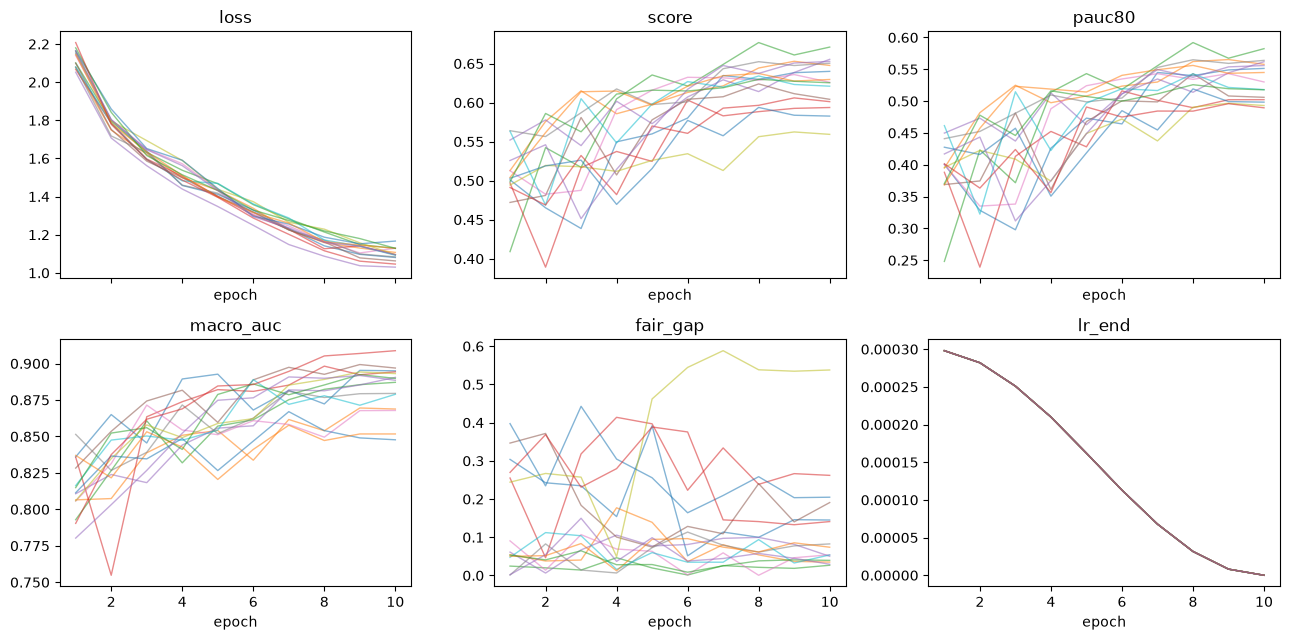

best epoch in the log == checkpoint's stored epoch for all 15: True


,seed,fold,epoch,score,manifest_best_epoch,match
0,42,0,10,0.6400,10,True
1,42,1,9,0.6529,9,True
2,42,2,8,0.6769,8,True
3,42,3,6,0.6032,6,True
4,42,4,10,0.6554,10,True
5,43,0,8,0.6239,8,True
6,43,1,9,0.6359,9,True
7,43,2,8,0.6524,8,True
8,43,3,9,0.5624,9,True
9,43,4,8,0.6341,8,True


In [8]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True)
for ax, col in zip(axes.flat, ["loss", "score", "pauc80", "macro_auc", "fair_gap", "lr_end"]):
    for (seed, fold), g in hist.groupby(["seed", "fold"]):
        ax.plot(g.epoch, g[col], alpha=0.55, lw=1)
    ax.set_title(col)
    ax.set_xlabel("epoch")
savefig("fig_history")
best = hist.loc[hist.groupby(["seed", "fold"]).score.idxmax(), ["seed", "fold", "epoch", "score"]]
manifest = json.loads(inp("manifest").read_text())
mf = pd.DataFrame([{"seed": c["seed"], "fold": c["fold"], "manifest_best_epoch": c["best_epoch"]}
                   for c in manifest["checkpoints"]])
best = best.merge(mf, on=["seed", "fold"])
best["match"] = best.epoch == best.manifest_best_epoch
best.to_csv(out("table_best_epochs"), index=False)
print("best epoch in the log == checkpoint's stored epoch for all 15:", bool(best.match.all()))
best

The best epoch read from the logs matches the epoch stored in every checkpoint. 14 of the 15 folds peak at epochs 8–10,
but only three at the final epoch, while the training loss keeps falling. That is a late plateau rather than
undertraining, which is why we did not prioritise longer training.

## 8. Training environment
Which software trained the checkpoints?

In [9]:
rt = json.loads(inp("runtime").read_text())
display(pd.DataFrame(rt["training_runs"]))
{k: rt["training_env"][k] for k in ("python", "torch", "cuda", "cudnn", "gpus", "preinstalled")}

,name,seed,extra,returncode,minutes
0,P1a-kg-s42,42,[],0,39.6
1,P1a-kg-s43,43,[],0,40.3
2,P1a-kg-s44,44,[],0,40.5


{'python': '3.12.13',
 'torch': '2.10.0+cu128',
 'cuda': '12.8',
 'cudnn': 91002,
 'gpus': ['Tesla T4', 'Tesla T4'],
 'preinstalled': {'albumentations': '2.0.8',
  'albucore': '0.0.24',
  'timm': '1.0.26',
  'opencv-python': '4.13.0.92',
  'opencv-python-headless': '4.13.0.92',
  'numpy': '2.0.2',
  'pandas': '2.3.3',
  'scikit-learn': '1.6.1',
  'pydantic': '2.12.3'}}

The checkpoints were trained with Python 3.12.13 and torch 2.10.0 on a T4, while this notebook runs with torch 2.14.
The README explains why that matters only for exact reproduction, not for the results.

## Takeaways
- A 23.7 M-parameter two-stream model with token fusion, trained with focal loss + BCE, sqrt-balanced sampling and a cosine schedule.
- Training curves plateau late without clear undertraining.
- The demo shows that the training code runs end to end; full retraining is documented but left off.

Next, notebook 05 evaluates the released ensemble.